DSCI 552 Homework 6
===================

- Name: Karan Timmala
- GitHub Username: karantimmala
- USD ID: 1373267232

In [1]:
!pip install xgboost

In [2]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline as SklearnPipeline
RANDOM_STATE = 42
CV_FOLDS = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. Tree-Based Methods
## (a) APS failure data
The supplied split has 60,000 training and 16,000 test observations, with
170 numeric predictors and a binary class label.

In [3]:
# Skip the CSV metadata and treat the dataset's "na" entries as missing values.
def locate_csv(filename):
    folders = [Path('.'), Path('data'), Path('../data'), Path('upload'), Path('../upload')]
    for folder in folders:
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Place {filename} beside the notebook or in a data folder.')
training_data = pd.read_csv(locate_csv('aps_failure_training_set.csv'), skiprows=20, na_values='na')
testing_data = pd.read_csv(locate_csv('aps_failure_test_set.csv'), skiprows=20, na_values='na')
print('Training shape:', training_data.shape)
print('Test shape:', testing_data.shape)
print('Number of predictors:', training_data.shape[1] - 1)

Training shape: (60000, 171)
Test shape: (16000, 171)
Number of predictors: 170


In [4]:
print(training_data["class"].value_counts())
print(training_data["class"].value_counts(normalize=True))

class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    0.983333
pos    0.016667
Name: proportion, dtype: float64


In [5]:
print(testing_data["class"].value_counts())
print(testing_data["class"].value_counts(normalize=True))

class
neg    15625
pos      375
Name: count, dtype: int64
class
neg    0.976562
pos    0.023438
Name: proportion, dtype: float64


## (b) Data preparation
### (i) Missing-value treatment

Common options include mean/median, nearest-neighbor, regression/iterative,
and multiple imputation. Median imputation is used because the predictors
are skewed and contain extreme values. It fills 850,015 missing training
entries and 228,680 test entries, retaining all observations. Separate
test medians follow the PDF footnote; test labels are excluded. During CV,
the imputer is fitted only on each fold's training partition.

In [6]:
X_train_raw = training_data.drop(columns='class').copy()
X_test_raw = testing_data.drop(columns='class').copy()
y_train = training_data['class'].map({'neg': 0, 'pos': 1})
y_test = testing_data['class'].map({'neg': 0, 'pos': 1})
print('Missing entries before imputation (train):', X_train_raw.isna().sum().sum())
print('Missing entries before imputation (test):', X_test_raw.isna().sum().sum())
# Separate test imputation follows the explicit footnote in Homework6.pdf.
train_imputer = SimpleImputer(strategy='median')
test_imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(train_imputer.fit_transform(X_train_raw),
                       columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(test_imputer.fit_transform(X_test_raw),
                      columns=X_test_raw.columns, index=X_test_raw.index)
print('Missing entries after imputation (train):', X_train.isna().sum().sum())
print('Missing entries after imputation (test):', X_test.isna().sum().sum())

Missing entries before imputation (train): 850015
Missing entries before imputation (test): 228680
Missing entries after imputation (train): 0
Missing entries after imputation (test): 0


### (ii) Coefficient of variation
For all 170 training predictors, $CV=s/m$ uses sample standard deviation
(`ddof=1`). The results are ratios, not percentages. The largest CVs are
`cf_000` (244.8875), `co_000` (244.5074), and `ad_000` (244.3228).
Constant `cd_000` has CV zero. All values are arranged in four column groups.

In [7]:
# Use sample standard deviation and leave CV undefined when a feature mean is zero.
means = X_train.mean()
stds = X_train.std(ddof=1)
cv = stds.div(means.replace(0, np.nan))
variation_table = pd.DataFrame({'Feature': X_train.columns, 'Mean': means.values,
                       'StdDev': stds.values, 'CV': cv.values})
print('CV values calculated for all', len(variation_table), 'predictors (CV = sample SD / mean).')
cv_columns = [variation_table[['Feature', 'CV']].iloc[idx]
              .reset_index(drop=True).set_axis([f'Feature {i+1}', f'CV {i+1}'], axis=1)
              for i, idx in enumerate(np.array_split(np.arange(len(variation_table)), 4))]
display(pd.concat(cv_columns, axis=1))

CV values calculated for all 170 predictors (CV = sample SD / mean).


,Feature 1,CV 1,Feature 2,CV 2,Feature 3,CV 3,Feature 4,CV 4
0,aa_000,2.450938,az_001,7.720873,ca_000,0.931790,cz_000,14.505585
1,ab_000,10.383494,az_002,13.271741,cb_000,0.909183,da_000,29.367527
2,ac_000,2.310241,az_003,7.527395,cc_000,2.524251,db_000,6.259495
3,ad_000,244.322816,az_004,2.848992,cd_000,0.000000,dc_000,1.725222
4,ae_000,24.200137,az_005,3.034680,ce_000,2.271205,dd_000,3.056522
5,af_000,19.471295,az_006,8.880568,cf_000,244.887517,de_000,4.527525
6,ag_000,92.917755,az_007,16.229427,cg_000,4.025089,df_000,52.292814
7,ag_001,35.249314,az_008,22.679650,ch_000,77.453857,dg_000,38.486162
8,ag_002,17.565907,az_009,77.838544,ci_000,2.400104,dh_000,123.216097
9,ag_003,8.647402,ba_000,2.699563,cj_000,11.069531,di_000,11.826232


### (iii) Correlation matrix
Warm blocks indicate correlated groups; many other pairs are near zero.
This suggests overlapping information, not feature significance. The blank
band for constant `cd_000` represents undefined Pearson correlation.

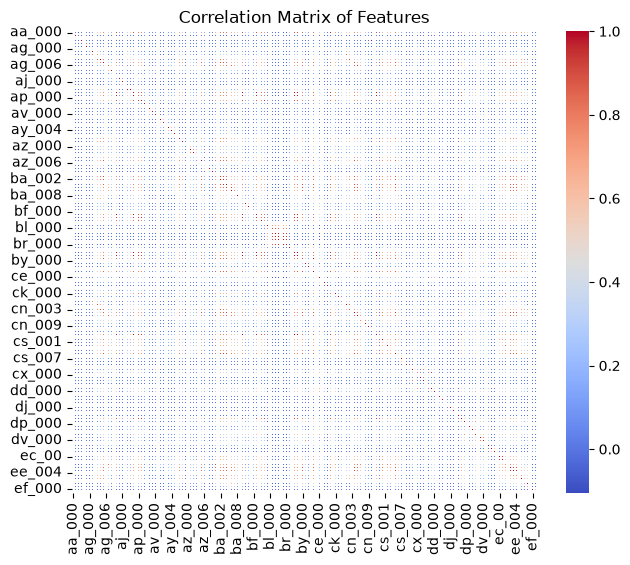

In [8]:
corr_matrix = X_train.corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_matrix, cmap="coolwarm", linewidths=0.1)
plt.title("Correlation Matrix of Features")
plt.show()

### (iv) Highest-CV features
Select $\lfloor\sqrt{170}\rfloor=13$ features for visualization only.
All subsequent models retain the full predictor set.

In [9]:
# Select high-CV features for visualization; every model still uses all 170 predictors.
top_k = math.floor(math.sqrt(X_train.shape[1]))
cv_sorted = variation_table.sort_values('CV', ascending=False, na_position='last')
visual_features = cv_sorted.iloc[:top_k]['Feature'].tolist()
display(cv_sorted.iloc[:top_k].reset_index(drop=True))

,Feature,Mean,StdDev,CV
0,cf_000,143107.534133,3.504525e+07,244.887517
1,co_000,143330.017733,3.504525e+07,244.507385
2,ad_000,143438.292067,3.504525e+07,244.322816
3,cs_009,770.509700,1.833278e+05,237.930554
4,dh_000,4392.640833,5.412441e+05,123.216097
5,dj_000,37.271333,4.379166e+03,117.494225
6,ag_000,219.157733,2.036364e+04,92.917755
7,as_000,125.407900,1.095219e+04,87.332500
8,ay_009,1149.619633,9.741156e+04,84.733735
9,ak_000,907.660700,7.299859e+04,80.424975


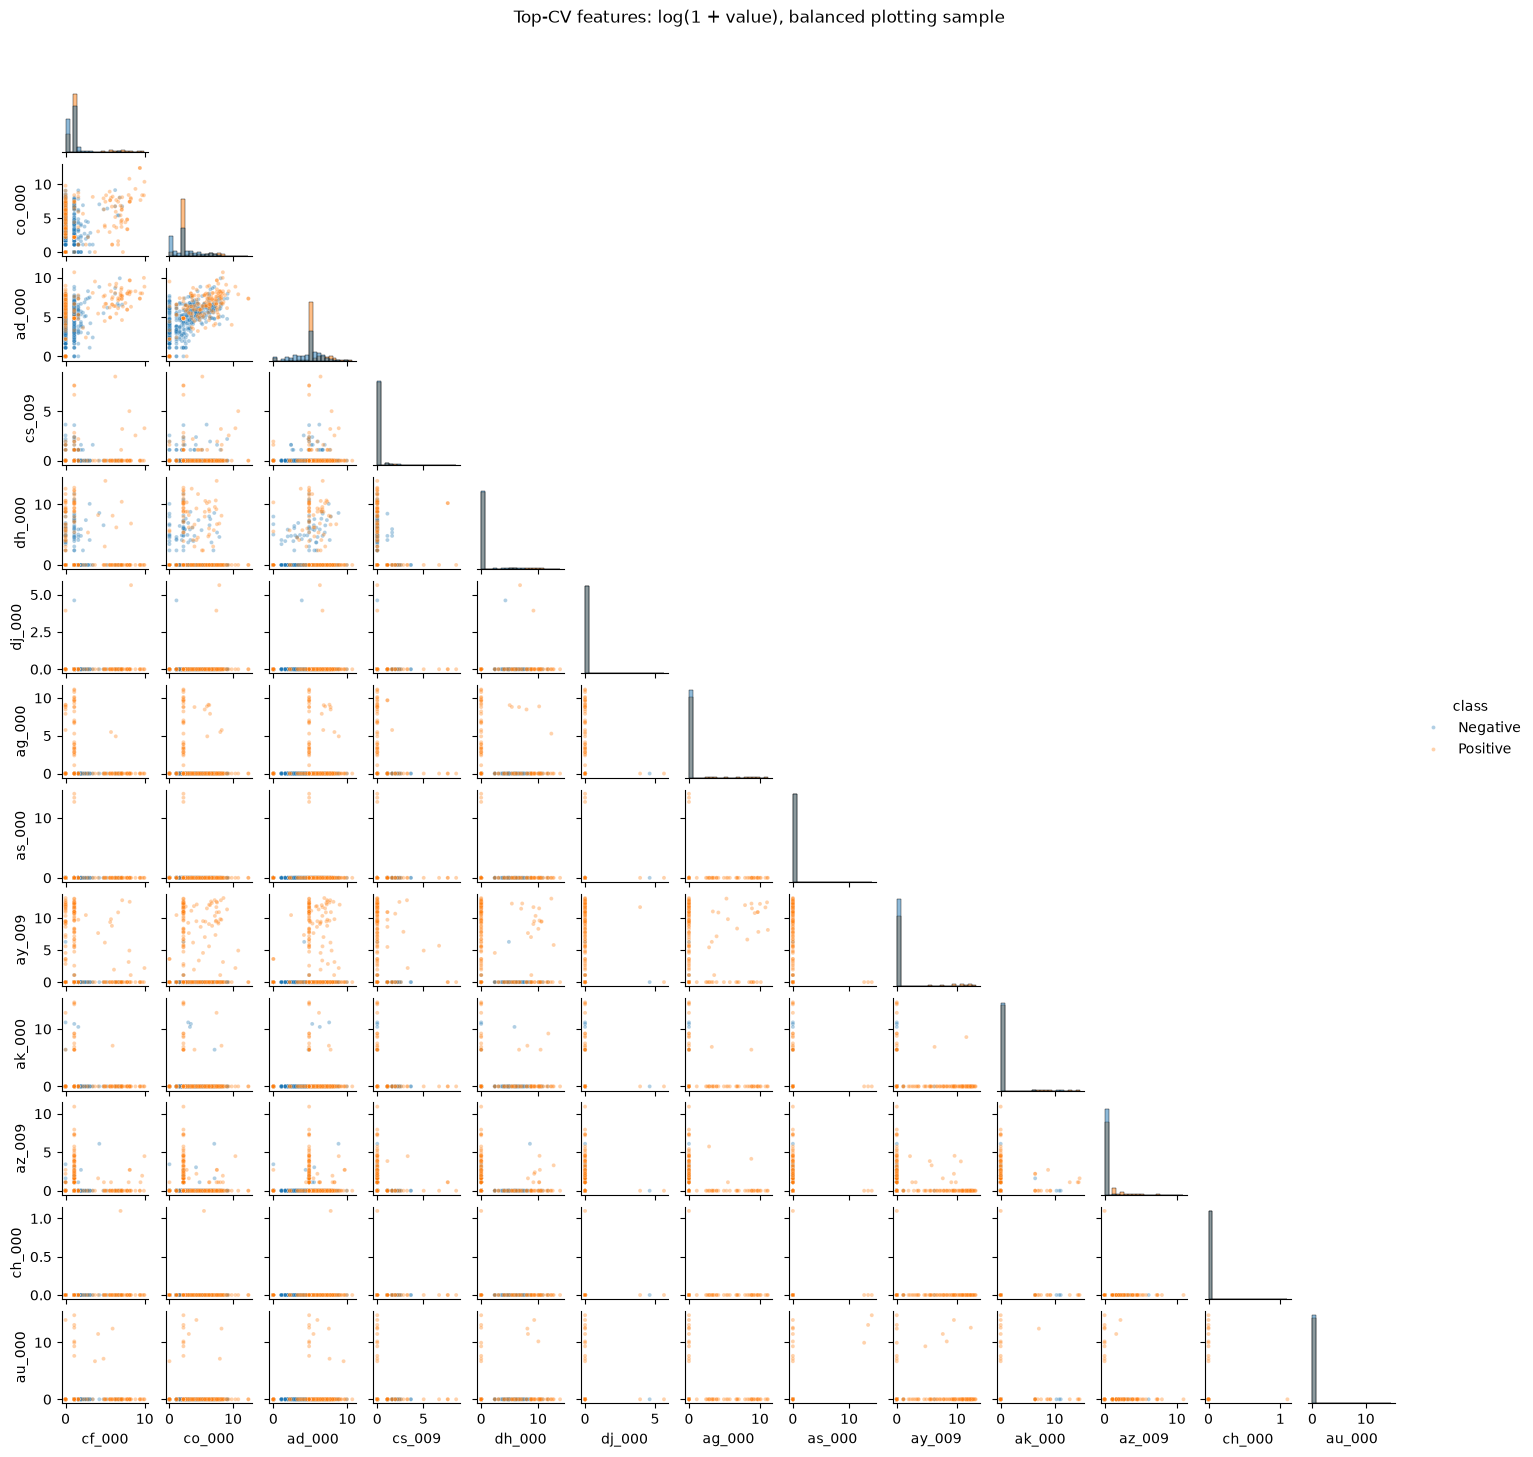

In [10]:
plot_df = X_train[visual_features].copy()
plot_df['class'] = y_train.map({0: 'Negative', 1: 'Positive'})
# Balance only the plotting sample so the rare class is visible.
plot_sample = pd.concat([
    group.sample(n=min(500, len(group)), random_state=RANDOM_STATE)
    for _, group in plot_df.groupby('class', sort=True)
])
scatter_df = plot_sample.copy()
scatter_df[visual_features] = np.log1p(scatter_df[visual_features])
scatter_grid = sns.pairplot(
    scatter_df, vars=visual_features, hue='class', hue_order=['Negative', 'Positive'],
    diag_kind='hist', corner=True, height=1.1,
    plot_kws={'alpha': 0.35, 's': 8}, diag_kws={'bins': 20}
)
scatter_grid.fig.suptitle('Top-CV features: log(1 + value), balanced plotting sample', y=1.02)
plt.show()

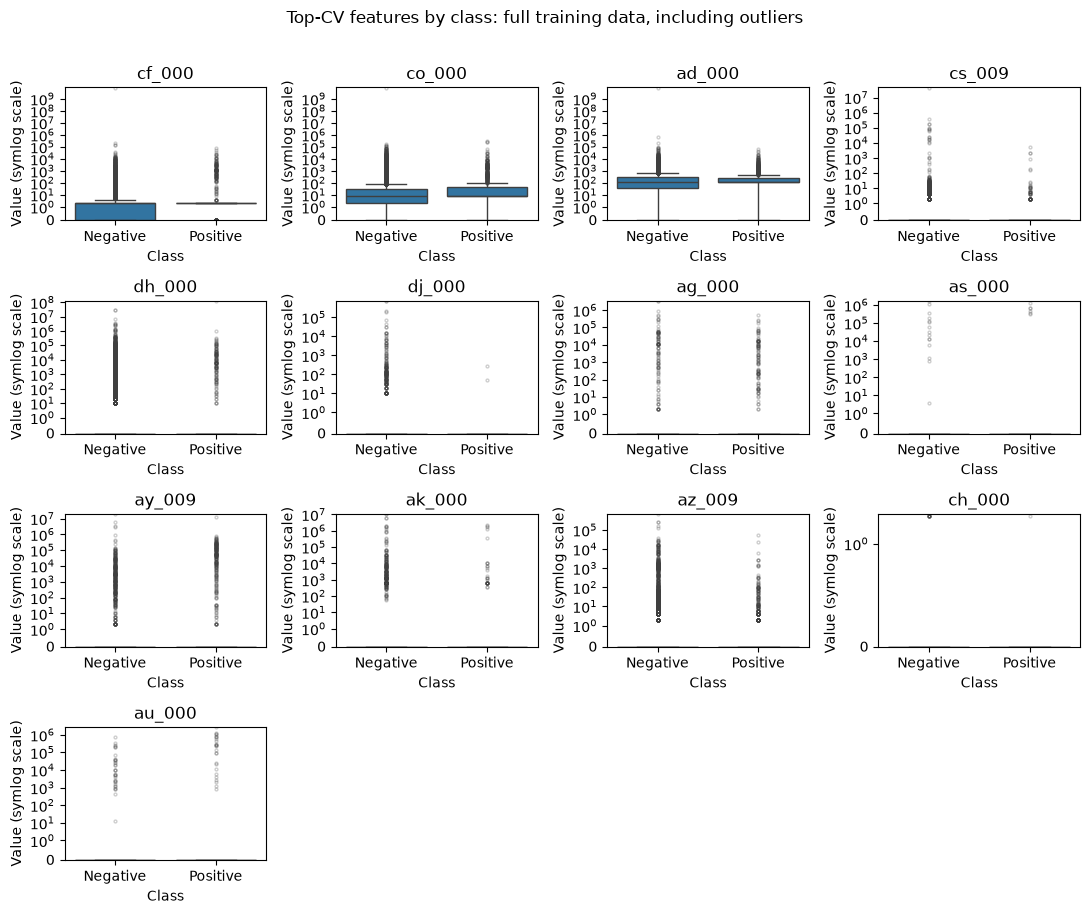

In [11]:
# A symmetric-log scale displays both zero values and large outliers.
box_df = X_train[visual_features].copy()
box_df['class'] = y_train.map({0: 'Negative', 1: 'Positive'})
fig, axes = plt.subplots(4, 4, figsize=(11, 9))
for ax, feature in zip(axes.ravel(), visual_features):
    sns.boxplot(data=box_df, x='class', y=feature,
                order=['Negative', 'Positive'], showfliers=True,
                flierprops={'markersize': 2, 'alpha': 0.25}, ax=ax)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_ylim(bottom=0)
    ax.set_title(feature)
    ax.set_xlabel('Class')
    ax.set_ylabel('Value (symlog scale)')
for ax in axes.ravel()[len(visual_features):]:
    ax.set_visible(False)
fig.suptitle('Top-CV features by class: full training data, including outliers', y=1.01)
plt.tight_layout()
plt.show()

### Plot interpretation
The scatter plots use 500 observations per class and `log(1 + value)`;
box plots use the full training data and a symmetric-log scale. Many values
are near zero, with a few large outliers. Class distributions overlap,
although `co_000` and `ad_000` show differences in their centers. **Plots
alone cannot establish significance:** high CV measures variability, and
overlap in two dimensions does not exclude useful multivariate relationships.

### (v) Class imbalance

In [12]:
class_counts = pd.DataFrame({
    'Training': y_train.value_counts().reindex([0, 1]),
    'Test': y_test.value_counts().reindex([0, 1])
}).rename(index={0: 'Negative', 1: 'Positive'})
class_counts['Combined'] = class_counts['Training'] + class_counts['Test']
display(class_counts)
print(f'Training positive percentage: {100 * y_train.mean():.4f}%')
print(f'Test positive percentage: {100 * y_test.mean():.4f}%')

,Training,Test,Combined
class,,,
Negative,59000,15625,74625
Positive,1000,375,1375


Training positive percentage: 1.6667%
Test positive percentage: 2.3438%


Training contains 59,000 negatives and 1,000 positives (**1.6667%**, ratio
59:1); testing contains 15,625 negatives and 375 positives (**2.3438%**).
Combined counts are 74,625 negatives and 1,375 positives. This is highly
imbalanced, so inspect false negatives and positive recall alongside accuracy.

## (c) Random forest without imbalance compensation

In [13]:
# Bootstrap sampling supplies the observations used to estimate OOB error.
baseline_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=4,
    oob_score=True
)
baseline_forest.fit(X_train, y_train)
y_train_pred = baseline_forest.predict(X_train)
y_test_pred = baseline_forest.predict(X_test)
cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_test_pred)
print("Train Confusion Matrix:\n", cm_train)
print("\nTest Confusion Matrix:\n", cm_test)

Train Confusion Matrix:
 [[59000     0]
 [    1   999]]

Test Confusion Matrix:
 [[15610    15]
 [  106   269]]


In [14]:
# ROC and AUC use positive-class probabilities rather than predicted labels.
y_train_prob = baseline_forest.predict_proba(X_train)[:, 1]
y_test_prob = baseline_forest.predict_proba(X_test)[:, 1]
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)
print("Train AUC:", auc_train)
print("Test AUC:", auc_test)

Train AUC: 1.0
Test AUC: 0.9927564799999999


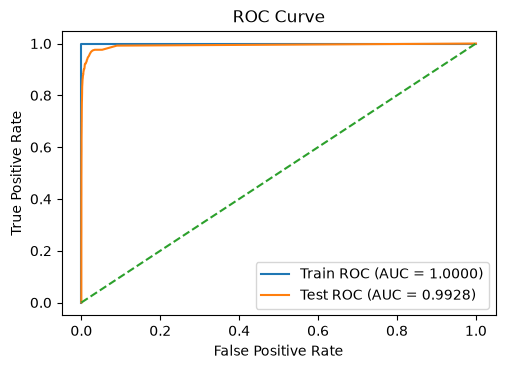

In [15]:
plt.figure(figsize=(5.6, 3.7))
plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {auc_train:.4f})")
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {auc_test:.4f})")
plt.plot([0,1], [0,1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [16]:
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
train_error = 1 - train_acc
test_error = 1 - test_acc
print("Train Misclassification Error:", train_error)
print("Test Misclassification Error:", test_error)

Train Misclassification Error: 1.666666666666483e-05
Test Misclassification Error: 0.0075625000000000275


In [17]:
# Compare the internal OOB estimate with error on the supplied test set.
oob_error = 1 - baseline_forest.oob_score_
print(f'OOB error: {oob_error:.6f}')
print(f'Test error: {test_error:.6f}')
print(f'Test minus OOB error: {test_error - oob_error:+.6f}')

OOB error: 0.006167
Test error: 0.007563
Test minus OOB error: +0.001396


### Results
Confusion-matrix rows are actual classes and columns predicted classes,
ordered Negative then Positive. Training has one false negative and no
false positives (error **0.00167%**, AUC **1.000000**). Testing has 15 false
positives and 106 false negatives: recall **71.73%**, error **0.75625%**,
and AUC **0.992756**. Low total error therefore coexists with missed failures.
OOB error **0.6167%** is about **0.1396 percentage points** below test error;
the near-perfect training fit is not an independent generalization estimate.

## (d) Random forest with class weights
Imbalance can be addressed through weighting, oversampling, undersampling,
or balanced bootstrap sampling. Here, `class_weight='balanced'` gives greater
weight to minority observations; the remaining forest settings are retained.

C:\Users\karan\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Balanced Train Confusion Matrix:
 [[58986    14]
 [    0  1000]]

Balanced Test Confusion Matrix:
 [[15571    54]
 [   99   276]]
Balanced Train AUC: 1.0
Balanced Test AUC: 0.9944034133333333


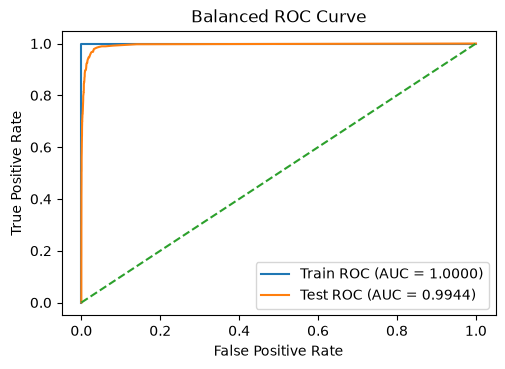

Balanced Train Misclassification Error: 0.00023333333333330764
Balanced Test Misclassification Error: 0.00956250000000003
Balanced OOB Score: 0.9797833333333333
Balanced OOB Error: 0.02021666666666666


In [18]:
# Inverse-frequency class weights increase the influence of minority observations.
weighted_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=4,
    oob_score=True,
    class_weight="balanced"
)
weighted_forest.fit(X_train, y_train)
y_train_pred_bal = weighted_forest.predict(X_train)
y_test_pred_bal = weighted_forest.predict(X_test)
cm_train_bal = confusion_matrix(y_train, y_train_pred_bal)
cm_test_bal = confusion_matrix(y_test, y_test_pred_bal)
print("Balanced Train Confusion Matrix:\n", cm_train_bal)
print("\nBalanced Test Confusion Matrix:\n", cm_test_bal)
y_train_prob_bal = weighted_forest.predict_proba(X_train)[:, 1]
y_test_prob_bal = weighted_forest.predict_proba(X_test)[:, 1]
fpr_train_bal, tpr_train_bal, _ = roc_curve(y_train, y_train_prob_bal)
fpr_test_bal, tpr_test_bal, _ = roc_curve(y_test, y_test_prob_bal)
auc_train_bal = auc(fpr_train_bal, tpr_train_bal)
auc_test_bal = auc(fpr_test_bal, tpr_test_bal)
print("Balanced Train AUC:", auc_train_bal)
print("Balanced Test AUC:", auc_test_bal)
plt.figure(figsize=(5.6, 3.7))
plt.plot(fpr_train_bal, tpr_train_bal, label=f"Train ROC (AUC = {auc_train_bal:.4f})")
plt.plot(fpr_test_bal, tpr_test_bal, label=f"Test ROC (AUC = {auc_test_bal:.4f})")
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced ROC Curve")
plt.legend()
plt.show()
train_acc_bal = accuracy_score(y_train, y_train_pred_bal)
test_acc_bal = accuracy_score(y_test, y_test_pred_bal)
train_error_bal = 1 - train_acc_bal
test_error_bal = 1 - test_acc_bal
print("Balanced Train Misclassification Error:", train_error_bal)
print("Balanced Test Misclassification Error:", test_error_bal)
oob_score_bal = weighted_forest.oob_score_
oob_error_bal = 1 - oob_score_bal
print("Balanced OOB Score:", oob_score_bal)
print("Balanced OOB Error:", oob_error_bal)

### Comparison
Class weighting reduces test false negatives **106 to 99**, improving recall
**71.73% to 73.60%**, but increases false positives **15 to 54**. Test error
rises **0.75625% to 0.95625%**, while AUC improves **0.992756 to 0.994403**.
Training has 14 false positives and no false negatives (error **0.02333%**).
The table below retains both models' metrics. The saved weighted-forest run
warns that some observations lack OOB scores; verify its **2.0217% OOB error**
by rerunning. OOB scoring also does not refit imputation for each bootstrap.

In [19]:
rf_comparison = pd.DataFrame({
    'Uncompensated RF': {
        'Train error': train_error, 'Test error': test_error, 'OOB error': oob_error,
        'Train AUC': auc_train, 'Test AUC': auc_test,
        'Test false positives': cm_test[0, 1], 'Test false negatives': cm_test[1, 0],
        'Test positive recall': cm_test[1, 1] / cm_test[1].sum()
    },
    'Class-weighted RF': {
        'Train error': train_error_bal, 'Test error': test_error_bal, 'OOB error': oob_error_bal,
        'Train AUC': auc_train_bal, 'Test AUC': auc_test_bal,
        'Test false positives': cm_test_bal[0, 1], 'Test false negatives': cm_test_bal[1, 0],
        'Test positive recall': cm_test_bal[1, 1] / cm_test_bal[1].sum()
    }
})
display(rf_comparison.round(6))
print(f'Class weighting changes test error by {test_error_bal - test_error:+.6f}.')
recall_difference = cm_test_bal[1, 1] / cm_test_bal[1].sum() - cm_test[1, 1] / cm_test[1].sum()
print(f'Class weighting changes positive recall by {100 * recall_difference:+.3f} percentage points.')

,Uncompensated RF,Class-weighted RF
Train error,0.000017,0.000233
Test error,0.007563,0.009563
OOB error,0.006167,0.020217
Train AUC,1.000000,1.000000
Test AUC,0.992756,0.994403
Test false positives,15.000000,54.000000
Test false negatives,106.000000,99.000000
Test positive recall,0.717333,0.736000


Class weighting changes test error by +0.002000.
Class weighting changes positive recall by +1.867 percentage points.


## (e) L1-regularized XGBoost
Tune `reg_alpha` by five-fold stratified CV without compensating for imbalance.
The pipeline fits imputation within each training fold. Ordinary XGBoost
uses boosted trees with logistic loss and an L1 penalty on leaf weights;
it does not fit a separate logistic-regression model at every node.

In [20]:
from xgboost import XGBClassifier
# Fit imputation within each fold, using the original missing-value matrix.
xgb_pipeline = SklearnPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('xgb', XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                          random_state=RANDOM_STATE, n_jobs=4))
])
alpha_candidates = [0, 0.01, 0.1, 1, 10]
xgb_search = GridSearchCV(
    xgb_pipeline, {'xgb__reg_alpha': alpha_candidates},
    cv=CV_FOLDS, scoring='accuracy', n_jobs=1, refit=True
)
xgb_search.fit(X_train_raw, y_train)
best_alpha = xgb_search.best_params_['xgb__reg_alpha']
cv_error_xgb = 1 - xgb_search.best_score_
print('Selected reg_alpha:', best_alpha)
print(f'Selected-model 5-fold CV error: {cv_error_xgb:.6f}')

Selected reg_alpha: 0.01
Selected-model 5-fold CV error: 0.006333


In [21]:
# GridSearchCV already refits the selected pipeline on the full training set.
xgb_final = xgb_search.best_estimator_
y_train_pred_xgb = xgb_final.predict(X_train_raw)
# Test features were imputed separately above, following the PDF footnote.
y_test_pred_xgb = xgb_final.predict(X_test)
cm_train_xgb = confusion_matrix(y_train, y_train_pred_xgb, labels=[0, 1])
cm_test_xgb = confusion_matrix(y_test, y_test_pred_xgb, labels=[0, 1])
print('XGBoost training confusion matrix:\n', cm_train_xgb)
print('XGBoost test confusion matrix:\n', cm_test_xgb)

XGBoost training confusion matrix:
 [[59000     0]
 [    1   999]]
XGBoost test confusion matrix:
 [[15609    16]
 [   86   289]]


In [22]:
y_train_prob_xgb = xgb_final.predict_proba(X_train_raw)[:, 1]
y_test_prob_xgb = xgb_final.predict_proba(X_test)[:, 1]
fpr_train_xgb, tpr_train_xgb, _ = roc_curve(y_train, y_train_prob_xgb)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(y_test, y_test_prob_xgb)
auc_train_xgb = roc_auc_score(y_train, y_train_prob_xgb)
auc_test_xgb = roc_auc_score(y_test, y_test_prob_xgb)
print(f'XGBoost training AUC: {auc_train_xgb:.6f}')
print(f'XGBoost test AUC: {auc_test_xgb:.6f}')

XGBoost training AUC: 1.000000
XGBoost test AUC: 0.993658


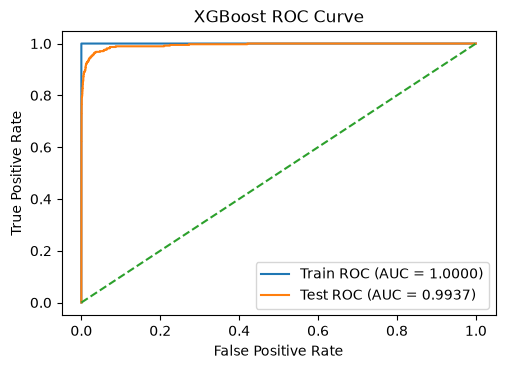

In [23]:
plt.figure(figsize=(5.6, 3.7))
plt.plot(fpr_train_xgb, tpr_train_xgb, label=f"Train ROC (AUC = {auc_train_xgb:.4f})")
plt.plot(fpr_test_xgb, tpr_test_xgb, label=f"Test ROC (AUC = {auc_test_xgb:.4f})")
plt.plot([0,1], [0,1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")
plt.legend()
plt.show()

In [24]:
train_error_xgb = 1 - accuracy_score(y_train, y_train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test, y_test_pred_xgb)
print(f'Training misclassification error: {train_error_xgb:.6f}')
print(f'5-fold CV misclassification error: {cv_error_xgb:.6f}')
print(f'Test misclassification error: {test_error_xgb:.6f}')
print(f'Test minus CV error: {test_error_xgb - cv_error_xgb:+.6f}')

Training misclassification error: 0.000017
5-fold CV misclassification error: 0.006333
Test misclassification error: 0.006375
Test minus CV error: +0.000042


### CV and test comparison
Selected alpha is **0.01**, with CV error about **0.6333%**. Test error
**0.63750%** differs by only **0.0042 percentage points**. The test matrix
contains 16 false positives and 86 false negatives (289/375 positives
detected; recall **77.07%**, AUC **0.993658**). Training has one error
(**0.00167%**) and reported AUC **1.000000**. Similar CV/test errors support
comparable performance here, but do not prove no overfitting: CV also selected
alpha, and training scores are in-sample.

## (f) SMOTE and XGBoost
Apply SMOTE only inside each CV training partition, following imputation.
Validation/test observations retain their original distributions. The final
fit has 59,000 observations per class; training metrics use the original 60,000.

In [ ]:
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.over_sampling import SMOTE
# Both imputation and SMOTE are fitted only on each CV training partition.
smote_pipeline = ImbalancedPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('xgb', XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                          random_state=RANDOM_STATE, n_jobs=4))
])
smote_search = GridSearchCV(
    smote_pipeline, {'xgb__reg_alpha': alpha_candidates},
    cv=CV_FOLDS, scoring='accuracy', n_jobs=1, refit=True
)
smote_search.fit(X_train_raw, y_train)
best_alpha_smote = smote_search.best_params_['xgb__reg_alpha']
cv_error_smote = 1 - smote_search.best_score_
print('Selected SMOTE reg_alpha:', best_alpha_smote)
print(f'Selected-model 5-fold CV error: {cv_error_smote:.6f}')
resampled_counts = y_train.value_counts().sort_index().copy()
for label, added in smote_search.best_estimator_.named_steps['smote'].sampling_strategy_.items():
    resampled_counts.loc[label] += added
print('Final full-training class counts after SMOTE:', resampled_counts.to_dict())

In [ ]:
xgb_smote_final = smote_search.best_estimator_
# Evaluate the original observations; prediction does not apply SMOTE.
y_train_pred_sm = xgb_smote_final.predict(X_train_raw)
y_test_pred_sm = xgb_smote_final.predict(X_test)
y_train_prob_sm = xgb_smote_final.predict_proba(X_train_raw)[:, 1]
y_test_prob_sm = xgb_smote_final.predict_proba(X_test)[:, 1]
cm_train_sm = confusion_matrix(y_train, y_train_pred_sm, labels=[0, 1])
cm_test_sm = confusion_matrix(y_test, y_test_pred_sm, labels=[0, 1])
auc_train_sm = roc_auc_score(y_train, y_train_prob_sm)
auc_test_sm = roc_auc_score(y_test, y_test_prob_sm)
train_error_sm = 1 - accuracy_score(y_train, y_train_pred_sm)
test_error_sm = 1 - accuracy_score(y_test, y_test_pred_sm)
print('SMOTE model confusion matrix: original 60,000 training observations:\n', cm_train_sm)
print('SMOTE model test confusion matrix:\n', cm_test_sm)
print(f'Training AUC: {auc_train_sm:.6f}')
print(f'Test AUC: {auc_test_sm:.6f}')
print(f'Training misclassification error: {train_error_sm:.6f}')
print(f'5-fold CV misclassification error: {cv_error_smote:.6f}')
print(f'Test misclassification error: {test_error_sm:.6f}')
print(f'Test minus CV error: {test_error_sm - cv_error_smote:+.6f}')
fpr_train_sm, tpr_train_sm, _ = roc_curve(y_train, y_train_prob_sm)
fpr_test_sm, tpr_test_sm, _ = roc_curve(y_test, y_test_prob_sm)
plt.figure(figsize=(5.6, 3.7))
plt.plot(fpr_train_sm, tpr_train_sm, label=f'Train ROC (AUC = {auc_train_sm:.4f})')
plt.plot(fpr_test_sm, tpr_test_sm, label=f'Test ROC (AUC = {auc_test_sm:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SMOTE + XGBoost: original training and test observations')
plt.legend()
plt.show()
xgb_comparison = pd.DataFrame({
    'XGBoost without SMOTE': {
        'Selected alpha': best_alpha, 'CV error': cv_error_xgb,
        'Train error (original data)': train_error_xgb, 'Test error': test_error_xgb,
        'Train AUC (original data)': auc_train_xgb, 'Test AUC': auc_test_xgb,
        'Test false positives': cm_test_xgb[0, 1], 'Test false negatives': cm_test_xgb[1, 0],
        'Test positive recall': cm_test_xgb[1, 1] / cm_test_xgb[1].sum()
    },
    'XGBoost with SMOTE': {
        'Selected alpha': best_alpha_smote, 'CV error': cv_error_smote,
        'Train error (original data)': train_error_sm, 'Test error': test_error_sm,
        'Train AUC (original data)': auc_train_sm, 'Test AUC': auc_test_sm,
        'Test false positives': cm_test_sm[0, 1], 'Test false negatives': cm_test_sm[1, 0],
        'Test positive recall': cm_test_sm[1, 1] / cm_test_sm[1].sum()
    }
})
display(xgb_comparison.round(6))
fn_change = int(cm_test_sm[1, 0] - cm_test_xgb[1, 0])
fp_change = int(cm_test_sm[0, 1] - cm_test_xgb[0, 1])
recall_change = cm_test_sm[1, 1] / cm_test_sm[1].sum() - cm_test_xgb[1, 1] / cm_test_xgb[1].sum()
print('SMOTE minus uncompensated XGBoost:')
print(f'False negatives: {fn_change:+d}; false positives: {fp_change:+d}')
print(f'Positive recall change: {100 * recall_change:+.3f} percentage points')
print(f'Test error change: {test_error_sm - test_error_xgb:+.6f}')
print(f'Test AUC change: {auc_test_sm - auc_test_xgb:+.6f}')

### Comparison with uncompensated XGBoost
Both models select **alpha = 0.01**. SMOTE increases test recall **77.07%
to 85.07%** (289 to 319 detected failures) and reduces false negatives
**86 to 56**, but raises false positives **16 to 68**. Test mistakes increase
102 to 124: error rises **0.63750% to 0.77500%** and AUC falls **0.993658
to 0.991278**. SMOTE CV error **0.6317%** is slightly lower, but its gap
to test error is **0.1433 percentage points**. Thus failure detection improves
at the default threshold, with more false alarms. Both models' original-training
errors are **0.00167%**; the preceding table retains all train/test metrics.

# 2. ISLR 6.6.3
As the constraint bound $s$ increases:

**(a) (iv) Training RSS decreases:** relaxing the constraint cannot worsen
the optimized training fit. **(b) (ii) Test RSS decreases, then increases:**
reduced underfitting is eventually offset by variance. **(c) (iii) Variance
increases:** the fit becomes more sample-sensitive. **(d) (iv) Squared bias
decreases:** flexibility reduces systematic underfitting. **(e) (v) Irreducible
error stays constant:** the data-generating noise is unchanged.

# 3. ISLR 6.6.5
Let $x_{i1}=x_{i2}=x_i$ for $i=1,2$, with intercept zero and $\lambda>0$.

**(a) Ridge optimization:**
$$\min_{\beta_1,\beta_2}\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$
**(b)** For fixed $c=\beta_1+\beta_2$, the residual loss is unchanged, while
$$\beta_1^2+\beta_2^2=\frac{c^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.$$
This penalty is minimized at $\hat\beta_1=\hat\beta_2=c/2$.

**(c) Lasso optimization:**
$$\min_{\beta_1,\beta_2}\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$
**(d)** For fixed sum $c$, $|\beta_1|+|\beta_2|\geq|c|$, with equality for
same-sign coefficients (allowing zero). If $c^*$ minimizes
$$\sum_{i=1}^{2}(y_i-x_i c)^2+\lambda|c|,$$
every pair $(t,c^*-t)$ is optimal for $0\leq t\leq c^*$ when $c^*>0$, or
$c^*\leq t\leq0$ when $c^*<0$. Examples include $(c^*,0)$, $(0,c^*)$, and
$(c^*/2,c^*/2)$. Nonzero optimal sums give multiple solutions; for $c^*=0$,
the penalty-minimizing pair is $(0,0)$.

# 4. ISLR 8.4.5
The Red probabilities are 0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60,
0.65, 0.70, 0.75. **Majority vote gives Red** (6 votes versus 4).
**Average probability gives Green:** $4.50/10=0.45<0.5$.

# 5. ISLR 9.7.3

### (a) Sketch the observations

In [ ]:
red = [(3, 4), (2, 2), (4, 4), (1, 4)]
blue = [(2, 1), (4, 3), (4, 1)]
red_x = [p[0] for p in red]
red_y = [p[1] for p in red]
blue_x = [p[0] for p in blue]
blue_y = [p[1] for p in blue]
plt.figure(figsize=(4, 4))
plt.scatter(red_x, red_y, color="red", s=100, label="Red")
plt.scatter(blue_x, blue_y, color="blue", s=100, label="Blue")
for i, (x, y) in enumerate(red, start=1):
    plt.text(x + 0.05, y + 0.05, f"r{i}", fontsize=10)
for i, (x, y) in enumerate(blue, start=5):
    plt.text(x + 0.05, y + 0.05, f"b{i}", fontsize=10)
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Observations")
plt.grid(True)
plt.legend()
plt.show()

The plotted Red points are (3,4), (2,2), (4,4), (1,4); Blue points are
(2,1), (4,3), (4,1). The classes are linearly separable.

### (b) Optimal separating hyperplane

In [ ]:
# Support points lie on the two parallel margin boundaries.
support_points = np.array([[2,2], [4,4], [4,3], [2,1]])
plt.figure(figsize=(4, 4))
plt.scatter(red_x, red_y, c='red', s=100, label='Red')
plt.scatter(blue_x, blue_y, c='blue', s=100, label='Blue')
plt.scatter(support_points[:,0], support_points[:,1], s=220, label='Support vectors', facecolors='none', edgecolors='black', linewidth=2)
x_vals = np.linspace(0, 5, 100)
main_line = x_vals - 0.5
upper_margin = x_vals
lower_margin = x_vals - 1
plt.plot(x_vals, main_line, color='green', linewidth=2, label='Optimal Separating Hyperplane')
plt.plot(x_vals, upper_margin, linestyle='--', color='black')
plt.plot(x_vals, lower_margin, linestyle='--', color='black')
plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(0,5)
plt.ylim(0,5)
plt.title("Maximal Margin Classifier")
plt.legend()
plt.grid(True)
plt.show()

The optimal line lies halfway between $X_2=X_1$ and $X_2=X_1-1$:
$$X_2=X_1-\frac12,\qquad \frac12-X_1+X_2=0.$$

### (c) Classification rule
Use $f(X)=1/2-X_1+X_2$: classify **Red if $f(X)>0$**, otherwise Blue.
Thus $(\beta_0,\beta_1,\beta_2)=(1/2,-1,1)$. For example, $f(2,2)=1/2$
(Red), while $f(2,1)=-1/2$ (Blue).

### (d) Margins
The dashed supporting lines are $X_2=X_1$ and $X_2=X_1-1$. The normal
has length $\sqrt{2}$, so each margin is $1/(2\sqrt{2})$ and total width
is $1/\sqrt{2}$.

### (e) Support vectors
The circled support vectors are Red **(2,2), (4,4)** and Blue **(2,1), (4,3)**;
they lie on the margin boundaries.

### (f) Moving observation 7
Blue observation (4,1) is not a support vector. A sufficiently small move
that keeps it outside the margin leaves the maximal margin separator unchanged.

### (g) A nonoptimal separating hyperplane

In [ ]:
plt.figure(figsize=(4, 4))
plt.scatter(red_x, red_y, c='red', s=100, label='Red')
plt.scatter(blue_x, blue_y, c='blue', s=100, label='Blue')
x_vals = np.linspace(0, 5, 100)
opt_line = x_vals - 0.5
non_opt_line = x_vals - 0.2
plt.plot(x_vals, opt_line, color='green', linewidth=2, label='Optimal Hyperplane')
plt.plot(x_vals, non_opt_line, color='orange', linestyle='--', linewidth=2, label='Non-optimal Hyperplane')
plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(0,5)
plt.ylim(0,5)
plt.title("Non-optimal Separating Hyperplane")
plt.legend()
plt.grid(True)
plt.show()

The orange line $X_2=X_1-0.2$ separates all points, but has a smaller minimum
distance to them than the optimal line; it does not maximize the margin.

### (h) Add a point to destroy linear separability

In [ ]:
# A blue point on the red convex hull prevents strict linear separation.
added_blue_point = np.array([[2,4]])
plt.figure(figsize=(4, 4))
plt.scatter(red_x, red_y, c='red', s=100, label='Red')
plt.scatter(blue_x, blue_y, c='blue', s=100, label='Blue')
plt.scatter(added_blue_point[:,0], added_blue_point[:,1], c='blue', marker='x', s=150, linewidths=2, label='Additional Observation')
plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(0,5)
plt.ylim(0,5)
plt.title("Adding a Point to Break Linear Separability")
plt.legend()
plt.grid(True)
plt.show()

The new Blue point **(2,4)** lies in the Red convex hull:
$$(2,4)=\frac{2}{3}(1,4)+\frac{1}{3}(4,4).$$
A linear score positive at both Red endpoints must also be positive at this
combination, so it cannot assign the new point to Blue. Strict separation
is therefore impossible.

## References

- https://xgboost.readthedocs.io/en/stable/parameter.html
- https://xgboost.readthedocs.io/en/stable/tutorials/model.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://imbalanced-learn.org/stable/common_pitfalls.html
- https://seaborn.pydata.org/generated/seaborn.pairplot.html
- https://www.geeksforgeeks.org/machine-learning/linear-vs-non-linear-classification-
- https://www.geeksforgeeks.org/machine-learning/ml-bias-variance-trade-off/
- https://www.geeksforgeeks.org/machine-learning/smote-for-imbalanced-classification-with-python/


## AI used - ChatGPT (OpenAI)

### **Prompts**
- What is the step-by-step process for fitting and assessing an SVM binary classifier in Python, and how do you visualize its decision boundaries and margin limits?
- How do you utilize SMOTE to address skewed class distributions in Python while properly embedding it inside cross-validation loops to prevent data leakage?
- How can you set up a Random Forest model using scikit-learn, calculate the out-of-bag (OOB) error rate, and measure predictive performance via confusion matrices and ROC-AUC curves?
- How can you break down a confusion matrix to evaluate false positives and false negatives when dealing with heavily skewed class distributions?